# OULAD-Prediction
## Open University Learning Analytics Dataset(OULAD)
The Open University Learning Analytics Dataset contains data on seven selected courses, including information about the courses, students, and their interactions with the virtual learning environment. We use this dataset to predict if a student fails the subject based on their activities and backgrounds.

## Table of Content

- **0. Setup**
  - 0.1 Globally import libraries
  - 0.2 Set global constants
- **1. Data Preprocessing & Feature Engineering**
  - 1.1 Load raw tables
  - 1.2 Evidence for the report
  - 1.3 Clean `studentInfo` and construct the target
  - 1.4 Aggregate to enrolment level and define the feature sets
  - 1.5 Shared harness (splitting, preprocessing)
- **2. Classical ML Models**
  - 2.0 Config
  - 2.1 Baseline model
  - 2.2 Logistic Regression
  - 2.3 Decision Tree
  - 2.4 Random Forest
  - 2.5 Delivery
- **3. Neural Network**
  - 3.1 Train and tune the MLP
  - 3.2 Sample results
  - 3.3 Tuning curve
  - 3.4 Delivery
- **4. Results**
  - 4.1 Visualize results to compare different feature groups' performance by cutoff days
  - 4.2 Error analysis

---

## 0. Setup

**To produce results, simply run the notebook, or run each code block in sequential order**

### 0.1 Globally import libraries

Import all necessary libraries at once in case of duplication

In [51]:
# data handling
import json, sys, types
from pathlib import Path

# data + plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# scikit-learn: tools
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

# scikit-learn: classical models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
# scikit-learn: Neural Network
from sklearn.neural_network import MLPClassifier

### 0.2 Set global constants

Name constants used across code blocks

In [52]:
SEED = 42
KEY = ["code_module", "code_presentation", "id_student"]
CUTOFF_DAYS = [0, 24, 60, 120]
VLE_WINDOW_START = -25
RANDOM_SEED = SEED
GROUP_COL = "id_student"
TARGET = "at_risk"
MAIN_CUTOFF = 24
FEATURE_SET_NAMES = ("baseline", "behaviour", "engineered")
TARGET = "at_risk"
GROUP_COL = "id_student"

---

## 1. Data Preprocessing & Feature Engineering
### 1.1 Load raw tables
⚠ We assume there is a "data" folder that contains the data files

In [53]:
DATA_DIR = Path("data")

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

# Missing values are encoded as the string "?", not as empty fields.
NA = ["?"]
student_info = pd.read_csv(DATA_DIR / "studentInfo.csv", na_values=NA)
student_reg = pd.read_csv(DATA_DIR / "studentRegistration.csv", na_values=NA)
student_asm = pd.read_csv(DATA_DIR / "studentAssessment.csv", na_values=NA)
assessments = pd.read_csv(DATA_DIR / "assessments.csv", na_values=NA)
vle_meta = pd.read_csv(DATA_DIR / "vle.csv", na_values=NA)
courses = pd.read_csv(DATA_DIR / "courses.csv", na_values=NA)

# studentVle is 10.7M rows; explicit dtypes cut memory from ~1.5 GB to ~250 MB.
VLE_DTYPES = {
    "code_module": "category",
    "code_presentation": "category",
    "id_student": "int32",
    "id_site": "int32",
    "date": "int16",
    "sum_click": "int32",
}
student_vle = pd.read_csv(DATA_DIR / "studentVle.csv", dtype=VLE_DTYPES, na_values=NA)
student_vle.shape

(10655280, 6)

### 1.2 Evidence for the report
Measures non-obvious properties of the dataset, each quantified here so Section 3.1 can cite a number
#### 1.2.1 Missing values are encoded as the string `?`

In [54]:
# Reading each file twice, with and without na_values, shows how the "?" marker
# changes both the reported missing rate and the inferred dtype.
rows = []
for name in ["studentInfo", "studentRegistration", "studentAssessment", "vle"]:
    raw = pd.read_csv(DATA_DIR / f"{name}.csv")
    fixed = pd.read_csv(DATA_DIR / f"{name}.csv", na_values=NA)
    for col in raw.columns:
        n = (raw[col].astype(str).str.strip() == "?").sum()
        if n:
            rows.append({"table": name, "column": col, "n_question_marks": n,
                         "share_%": round(n / len(raw) * 100, 2),
                         "missing_rate_default_%": round(raw[col].isna().mean() * 100, 2),
                         "dtype_default": str(raw[col].dtype),
                         "dtype_corrected": str(fixed[col].dtype)})
evidence_1 = pd.DataFrame(rows)
evidence_1

,table,column,n_question_marks,share_%,missing_rate_default_%,dtype_default,dtype_corrected
0,studentInfo,imd_band,1111,3.41,0.0,str,str
1,studentRegistration,date_registration,45,0.14,0.0,str,float64
2,studentRegistration,date_unregistration,22521,69.10,0.0,str,float64
3,studentAssessment,score,173,0.10,0.0,str,float64
4,vle,week_from,5243,82.39,0.0,str,float64
5,vle,week_to,5243,82.39,0.0,str,float64


#### 1.2.2 `date_unregistration` is target leakage
It is not used as a feature since it determines the target directly

In [55]:
# Evidence 2: Leakage check
chk = student_info.merge(student_reg, on=KEY, how="left")

evidence_2 = pd.crosstab(chk["final_result"],
                         chk["date_unregistration"].isna(),
                         normalize="index").round(4) * 100
evidence_2.columns = ["has_unregistration_date_%", "no_unregistration_date_%"]
evidence_2

,has_unregistration_date_%,no_unregistration_date_%
final_result,,
Distinction,0.00,100.00
Fail,0.13,99.87
Pass,0.00,100.00
Withdrawn,99.08,0.92


#### 1.2.3 Grouped structure — why a random split would not be valid
Quantifies how strongly a student's enrolments depend on each other

In [56]:
vc = student_info["id_student"].value_counts()

si = student_info.copy()
si["completed"] = si["final_result"].isin(["Pass", "Distinction"])

# Order presentations chronologically so "first" and "second" attempt are well defined.
ORDER = {"2013B": 0, "2013J": 1, "2014B": 2, "2014J": 3}
multi = (si[si["id_student"].isin(vc[vc > 1].index)]
         .assign(_o=lambda d: d["code_presentation"].map(ORDER))
         .sort_values(["id_student", "_o"]))
pairs = multi.groupby("id_student")["completed"].apply(list)
pairs = pairs[pairs.apply(len) >= 2]
first, second = pairs.apply(lambda x: x[0]), pairs.apply(lambda x: x[1])

evidence_3 = pd.DataFrame([
    {"quantity": "enrolments", "value": len(student_info)},
    {"quantity": "unique students", "value": student_info["id_student"].nunique()},
    {"quantity": "students with >1 enrolment", "value": int((vc > 1).sum())},
    {"quantity": "max enrolments per student", "value": int(vc.max())},
    {"quantity": "completion rate, overall %", "value": round(si["completed"].mean() * 100, 1)},
    {"quantity": "completion rate | first attempt completed %", "value": round(second[first].mean() * 100, 1)},
    {"quantity": "completion rate | first attempt failed %", "value": round(second[~first].mean() * 100, 1)},
])
evidence_3

,quantity,value
0,enrolments,32593.0
1,unique students,28785.0
2,students with >1 enrolment,3538.0
3,max enrolments per student,5.0
4,"completion rate, overall %",47.2
5,completion rate | first attempt completed %,55.9
6,completion rate | first attempt failed %,24.7


### 1.3 Clean `studentInfo` and construct the target

Binary target: Fail + Withdrawn → `at_risk = 1`; Pass + Distinction → `0`.

#### 1.3.1 Build the target

In [57]:
info = student_info.copy()

# Positive class is non-completion, so precision and recall map onto the two
# costs of an early-warning system.
info["at_risk"] = (~info["final_result"].isin(["Pass", "Distinction"])).astype("int8")

info["final_result"].value_counts(normalize=True).mul(100).round(2)

final_result
Pass           37.93
Withdrawn      31.16
Fail           21.64
Distinction     9.28
Name: proportion, dtype: float64

#### 1.3.2 Fix and encode ordered categories

In [58]:
# 1.3.2 Fix and encode ordered categories
# "10-20" is missing its "%" in 3,516 records; without the fix it would be a separate category.
info["imd_band"] = info["imd_band"].replace({"10-20": "10-20%"}).astype("string")

# imd_band, highest_education and age_band are ordered, so they become ranks, not one-hot.
info["imd_band_num"] = info["imd_band"].map({f"{i}-{i+10}%": i + 5 for i in range(0, 100, 10)}).astype("float32")

EDU_MAP = {"No Formal quals": 0, "Lower Than A Level": 1, "A Level or Equivalent": 2,
           "HE Qualification": 3, "Post Graduate Qualification": 4}
info["highest_education_ord"] = info["highest_education"].map(EDU_MAP).astype("float32")
info["age_band_ord"] = info["age_band"].map({"0-35": 0, "35-55": 1, "55<=": 2}).astype("float32")

#### 1.3.3 Merge registration and course info

In [59]:
info = info.merge(student_reg, on=KEY, how="left", validate="one_to_one")

# Negative date_registration means days before course start; flipped so larger = earlier.
info["reg_lead_days"] = -info["date_registration"]
info["reg_date_missing"] = info["date_registration"].isna().astype("int8")

# 234 records (0.72%) register after the course starts; flagged rather than dropped.
info["registered_after_start"] = (info["date_registration"] > 0).fillna(False).astype("int8")

# Course length varies from 234 to 269 days, so day counts are later turned into ratios.
info = info.merge(courses, on=["code_module", "code_presentation"], how="left")

assert len(info) == len(student_info)

### 1.4 Aggregate to enrolment level and define the feature sets

One row per enrolment — the triple (module, presentation, student) — per cutoff day.
The risk set and the cutoff truncation are both applied here.

#### 1.4.1 Prepare VLE and assessment sources

In [60]:
assert vle_meta["id_site"].is_unique
site2type = vle_meta.set_index("id_site")["activity_type"]

# Anchored to the full type list from vle.csv: types such as repeatactivity are not
# clicked before the early cutoffs, so deriving columns from observed types would
# give the four cutoffs different feature schemas.
ALL_ACTIVITY_TYPES = sorted(vle_meta["activity_type"].dropna().unique().tolist())

student_vle["activity_type"] = student_vle["id_site"].map(site2type).astype("category")
assert student_vle["activity_type"].isna().sum() == 0

# studentAssessment carries no module or presentation; both arrive via assessments.
asm = student_asm.merge(
    assessments[["id_assessment", "code_module", "code_presentation",
                 "assessment_type", "date", "weight"]],
    on="id_assessment", how="left", validate="many_to_one")

asm = asm.rename(columns={"date": "due_date"})
asm["days_early"] = asm["due_date"] - asm["date_submitted"]
asm.shape

(173912, 11)

#### 1.4.2 Aggregation functions

In [61]:
def _normalise_key(f):
    """Cast the key to str/int64 so category-dtype indexes join correctly."""
    f = f.reset_index()
    f["code_module"] = f["code_module"].astype(str)
    f["code_presentation"] = f["code_presentation"].astype(str)
    f["id_student"] = f["id_student"].astype("int64")
    return f.set_index(KEY)


def vle_features(svle, cutoff):
    """Aggregate clickstream to one row per enrolment, using days <= cutoff only."""
    w = svle[svle["date"] <= cutoff]
    if len(w) == 0:
        return pd.DataFrame(index=pd.MultiIndex.from_tuples([], names=KEY))

    g = w.groupby(KEY, observed=True)
    f = g.agg(
        vle_total_clicks=("sum_click", "sum"),
        vle_active_days=("date", "nunique"),
        vle_n_sites=("id_site", "nunique"),
        vle_max_clicks_day=("sum_click", "max"),
    )
    f["vle_mean_clicks_per_active_day"] = f["vle_total_clicks"] / f["vle_active_days"]

    # Trend: a declining trajectory should signal disengagement more than a flat low one.
    mid = (VLE_WINDOW_START + cutoff) / 2
    h1 = w[w["date"] <= mid].groupby(KEY, observed=True)["sum_click"].sum()
    h2 = w[w["date"] > mid].groupby(KEY, observed=True)["sum_click"].sum()
    f["vle_clicks_h1"] = h1.reindex(f.index).fillna(0)
    f["vle_clicks_h2"] = h2.reindex(f.index).fillna(0)
    f["vle_trend_ratio"] = (f["vle_clicks_h2"] + 1) / (f["vle_clicks_h1"] + 1)

    f["vle_clicks_before_start"] = (w[w["date"] <= 0].groupby(KEY, observed=True)["sum_click"]
                                    .sum().reindex(f.index).fillna(0))

    # Composition rather than volume: share of clicks per resource type.
    at = (w.groupby(KEY + ["activity_type"], observed=True)["sum_click"]
            .sum().unstack(fill_value=0))
    at = at.div(at.sum(axis=1).replace(0, np.nan), axis=0)
    at = at.reindex(columns=ALL_ACTIVITY_TYPES, fill_value=0.0)
    at.columns = ["vle_prop_" + str(col) for col in at.columns]

    return _normalise_key(f.join(at))


def asm_features(asm_df, cutoff):
    """Aggregate submissions to one row per enrolment, using submissions <= cutoff only."""
    w = asm_df[asm_df["date_submitted"] <= cutoff].copy()
    if len(w) == 0:
        return pd.DataFrame(index=pd.MultiIndex.from_tuples([], names=KEY))

    w["_wscore"] = w["score"] * w["weight"]
    f = w.groupby(KEY, observed=True).agg(
        asm_n_submitted=("id_assessment", "nunique"),
        asm_mean_score=("score", "mean"),
        asm_min_score=("score", "min"),
        asm_n_banked=("is_banked", "sum"),
        asm_mean_days_early=("days_early", "mean"),
        _wsum=("_wscore", "sum"),
        _wtot=("weight", "sum"),
    )
    f["asm_weighted_score"] = f["_wsum"] / f["_wtot"].replace(0, np.nan)
    return _normalise_key(f.drop(columns=["_wsum", "_wtot"]))

#### 1.4.3 Risk set and wide-table builder

Students who had already withdrawn before day *t* are excluded from the day-*t* table: for them the outcome has already occurred, so including them would be recording rather than predicting.

In [62]:
def build_wide_table(cutoff):
    """Build the day-`cutoff` wide table: risk set, truncated features, one row per enrolment."""
    base = info.copy()

    # Risk set: a student who withdrew on or before the cutoff already has an outcome,
    # so including them would be recording rather than predicting.
    already_withdrawn = base["date_unregistration"].notna() & (base["date_unregistration"] <= cutoff)
    n_excluded = int(already_withdrawn.sum())
    base = base.loc[~already_withdrawn].copy()

    vf = vle_features(student_vle, cutoff)
    af = asm_features(asm, cutoff)

    out = (base.set_index(KEY).join(vf, how="left").join(af, how="left").reset_index())

    vle_cols = [c for c in out.columns if c.startswith("vle_")]

    # Membership of the aggregate index, so the flags do not depend on column order.
    idx = pd.MultiIndex.from_frame(out[KEY])
    out["has_vle_activity"] = idx.isin(vf.index).astype("int8")
    out["has_asm_activity"] = idx.isin(af.index).astype("int8")
    n_zero_vle = int((out["has_vle_activity"] == 0).sum())

    # Count features impute to zero because no activity genuinely means zero;
    # proportions and means stay NaN so the modelling imputer handles them.
    count_like = [c for c in vle_cols if not any(k in c for k in ("prop", "trend", "mean"))]
    out[count_like] = out[count_like].fillna(0)
    out[["asm_n_submitted", "asm_n_banked"]] = out[["asm_n_submitted", "asm_n_banked"]].fillna(0)

    # Active days as a ratio, since the aggregation window length varies by cutoff.
    out["vle_active_days_ratio"] = out["vle_active_days"] / (cutoff - VLE_WINDOW_START + 1)
    out["cutoff_day"] = cutoff

    return out, dict(cutoff=cutoff, n_excluded=n_excluded, n=len(out),
                     n_students=out["id_student"].nunique(),
                     zero_vle=n_zero_vle, pos_rate=round(out["at_risk"].mean() * 100, 2))

### 1.4.4 Build all four cutoffs
The cutoffs are used to answer RQ1: How early can we predit if a student is at risk

Record data evolutions at day 0 (enrollment), 24, 60, 120

In [63]:
tables, summary = {}, []
for cut in CUTOFF_DAYS:
    t, s = build_wide_table(cut)
    tables[cut] = t
    summary.append(s)

# cleanup raw data
del student_vle, asm

summary = pd.DataFrame(summary)
summary

,cutoff,n_excluded,n,n_students,zero_vle,pos_rate
0,0,3097,29496,26358,5679,47.84
1,24,4780,27813,25068,1075,44.68
2,60,6232,26361,23985,563,41.64
3,120,7816,24777,22849,453,37.91


#### 1.4.5 The three feature sets

Feature set: all, behaviour, background
Used to answer RQ2: Which feature group is better between behaviour and background

In [64]:
sample = tables[CUTOFF_DAYS[1]]

# Known at registration.
BACKGROUND_CAT = ["code_module", "code_presentation", "gender", "region", "disability"]
BACKGROUND_NUM = ["highest_education_ord", "imd_band_num", "age_band_ord",
                  "num_of_prev_attempts", "studied_credits",
                  "reg_lead_days", "reg_date_missing", "registered_after_start",
                  "module_presentation_length"]

# Generated after enrolment.
BEHAVIOUR_NUM = [c for c in sample.columns if c.startswith(("vle_", "asm_"))] + \
                ["has_vle_activity", "has_asm_activity"]

# Never usable as features: the target itself, the leaking column, raw forms of
# already-encoded variables, the identifier, and the cutoff marker.
FORBIDDEN = ["final_result", "at_risk", "date_unregistration", "date_registration",
             "imd_band", "highest_education", "age_band", "id_student", "cutoff_day"]

FEATURE_SETS = {
    "background": BACKGROUND_CAT + BACKGROUND_NUM,
    "behaviour": BEHAVIOUR_NUM,
    "all": BACKGROUND_CAT + BACKGROUND_NUM + BEHAVIOUR_NUM,
}

# Guards so the three sets cannot drift apart if anyone edits the lists above.
assert set(FEATURE_SETS["all"]) == set(FEATURE_SETS["background"]) | set(FEATURE_SETS["behaviour"])
assert not (set(FEATURE_SETS["background"]) & set(FEATURE_SETS["behaviour"]))
for name, cols in FEATURE_SETS.items():
    assert all(c in sample.columns for c in cols)
    assert not any(c in FORBIDDEN for c in cols)

{name: len(cols) for name, cols in FEATURE_SETS.items()}

{'background': 14, 'behaviour': 38, 'all': 52}

#### 1.4.6 Skew diagnosis → `SKEWED_COLS`

Selection rule: skew > 2 **and** log reduces |skew| by ≥ 50% **and** max > 10 — so that 0–1 proportion columns, whose skew comes from sparsity rather than a long tail, are not selected.

In [65]:
rows = []
for col in [c for c in FEATURE_SETS["all"] if c not in BACKGROUND_CAT]:
    s = sample[col].dropna()
    if s.nunique() <= 2 or s.min() < 0:
        continue
    sk, skl = s.skew(), np.log1p(s).skew()
    rows.append({"column": col, "skew": round(sk, 2), "skew_after_log": round(skl, 2),
                 "reduction_%": round((abs(sk) - abs(skl)) / abs(sk) * 100, 1) if sk else 0.0,
                 "max": round(s.max(), 2)})

skew_table = pd.DataFrame(rows).sort_values("skew", ascending=False)

# Selected only if heavily skewed AND log halves the skew AND the column is a magnitude:
# the vle_prop_* columns are skewed through sparsity, not a long tail, so log does nothing.
selected = skew_table[(skew_table["skew"] > 2) &
                      (skew_table["reduction_%"] >= 50) &
                      (skew_table["max"] > 10)]
SKEWED_COLS = selected["column"].tolist()

selected.sort_values("reduction_%", ascending=False)

,column,skew,skew_after_log,reduction_%,max
33,asm_n_submitted,3.22,0.06,98.2,12.0
9,vle_max_clicks_day,31.66,-0.61,98.1,4098.0
11,vle_clicks_h1,5.28,-0.25,95.3,3731.0
14,vle_clicks_before_start,4.96,-0.35,93.0,3738.0
13,vle_trend_ratio,6.01,0.90,85.0,1791.0
12,vle_clicks_h2,3.45,-1.28,62.7,5643.0
6,vle_total_clicks,3.50,-1.35,61.3,7129.0


### 1.5 Shared harness

#### 1.5.1 Splitting: grouped by student, stratified on the target

Grouping so a student must never appear in both training and test data.

In [66]:
def make_splits(df, seed=SEED):
    """Split 60/20/20, grouped by student and stratified on the target."""
    y, g = df[TARGET], df[GROUP_COL]

    # 1 of 5 folds = 20% test
    outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    trainval_pos, test_pos = next(outer.split(df, y, g))
    trainval = df.iloc[trainval_pos].reset_index(drop=True)
    test = df.iloc[test_pos].reset_index(drop=True)

    # 1 of the remaining 4 folds = 20% validation
    inner = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=seed)
    tr_pos, val_pos = next(inner.split(trainval, trainval[TARGET], trainval[GROUP_COL]))
    train = trainval.iloc[tr_pos].reset_index(drop=True)
    val = trainval.iloc[val_pos].reset_index(drop=True)

    # No student may appear in more than one split.
    s_tr, s_va, s_te = (set(d[GROUP_COL]) for d in (train, val, test))
    assert not (s_tr & s_va) and not (s_tr & s_te) and not (s_va & s_te)

    return train, val, test


def describe_splits(train, val, test):
    """Split sizes and class balance, as reported in the Method section."""
    total = len(train) + len(val) + len(test)
    return pd.DataFrame([{
        "split": name,
        "n": len(d),
        "share_%": round(len(d) / total * 100, 1),
        "students": d[GROUP_COL].nunique(),
        "positive_%": round(d[TARGET].mean() * 100, 2),
    } for name, d in [("train", train), ("validation", val), ("test", test)]])

#### 1.5.2 Preprocessing

Fitted inside a `Pipeline` on training data only: fitting a scaler on the full dataset before
splitting would leak test statistics into training.

In [67]:
def _log1p_nonneg(X):
    """log(1 + x) with negatives clipped; a named function rather than a lambda so it pickles."""
    return np.log1p(np.clip(X, 0, None))


def make_preprocessor(cols, log_transform=False):
    """Impute, optionally log-transform skewed columns, scale numerics, one-hot categoricals."""
    cat = [c for c in cols if c in BACKGROUND_CAT]
    num = [c for c in cols if c not in cat]

    skewed = [c for c in num if c in SKEWED_COLS] if log_transform else []
    plain = [c for c in num if c not in skewed]

    num_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                         ("scale", StandardScaler())])
    skew_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("log", FunctionTransformer(_log1p_nonneg, feature_names_out="one-to-one")),
                          ("scale", StandardScaler())])
    cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                         ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])

    transformers = [("num", num_pipe, plain)]
    if skewed:
        transformers.append(("skew", skew_pipe, skewed))
    if cat:
        transformers.append(("cat", cat_pipe, cat))

    return ColumnTransformer(transformers, remainder="drop")

---

## 2. Classical ML Models

### 2.0 Config

#### 2.0.1 Split data by cutoffs & Split features by groups

Cutoffs: tables[0], tables[24], tables[60], tables[120]

Feature Groups: behaviour, background, all (behaviour+ background)

In [68]:
# one train/val/test split per cutoff (RQ1), grouped by student
SPLITS = {cut: make_splits(tables[cut]) for cut in CUTOFF_DAYS}

# define feature groups: background, behaviour, all for RQ2
# FEATURE_SETS reused from 1.4.5

#### 2.0.2 Evaluation metrics

6 metrics can be extracted. We use:

1. recall: how many at-risk students are successfully revealed in advanced
2. precision: the unnecessary warning made to safe students
3. macro-f1: the general performance over recall and precision

In [69]:
def evaluate(y_true, y_pred, y_proba=None):
    """Metric set used for every model; the positive class is non-completion."""
    out = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }
    if y_proba is not None:
        out["roc_auc"] = roc_auc_score(y_true, y_proba)
    return {k: round(float(v), 4) for k, v in out.items()}


def confusion(y_true, y_pred):
    """Confusion matrix with readable row and column labels."""
    return pd.DataFrame(confusion_matrix(y_true, y_pred),
                        index=["true: completed", "true: at risk"],
                        columns=["pred: completed", "pred: at risk"])


def score_model(model, cols, train, val, log_transform=False, fit_on=None):
    """Build the pipeline, fit it, and evaluate on `val`. Returns (pipeline, metrics)."""
    pipe = Pipeline([("prep", make_preprocessor(cols, log_transform)), ("clf", model)])
    fit_df = train if fit_on is None else fit_on
    pipe.fit(fit_df[cols], fit_df[TARGET])
    pred = pipe.predict(val[cols])
    proba = pipe.predict_proba(val[cols])[:, 1] if hasattr(pipe, "predict_proba") else None
    return pipe, evaluate(val[TARGET], pred, proba)

#### 2.0.3 `run_experiment()`
For each cutoff × feature set: Train -> tune on validation -> refit on train+val -> test

In [70]:
# run experiment for a given model, parameter (and values), cutoffs, and feature sets
def run_experiment(name, model, param, values, cutoffs=CUTOFF_DAYS, feature_sets=None):
    rows, curve, best_pipe = [], {}, None
    # using cutoffs to answer RQ1
    for cut in cutoffs:
        train, val, test = SPLITS[cut]
        train_val = pd.concat([train, val], ignore_index=True)
        for fs, cols in (feature_sets or FEATURE_SETS).items():
            # using feature sets to answer RQ2
            val_f1 = {}
            for v in values:
                # set model parameters
                m = clone(model).set_params(**{param: v})
                # fit on train, macro-F1 on val
                val_f1[v] = score_model(m, cols, train, val)[1]["macro_f1"]
            best = max(val_f1, key=val_f1.get)

            # refit best on train+val, score test once
            m = clone(model).set_params(**{param: best})
            pipe, scores = score_model(m, cols, train_val, test)
            rows.append({"model": name, "cutoff": cut, "feature_set": fs,
                         "best_param": f"{param}={best}", **scores})
            if cut == 24 and fs == "all":
                curve = val_f1
                best_pipe = pipe
    return rows, curve, best_pipe

#### 2.0.4 `plot_curve()`
Plot the tunning curve for model
cutoff = 24, feature = all

In [71]:
# plot the tuning curve for a given model
# the curve is a dict of {param_value: validation macro_f1}
# the curve is generated on the validation set for cutoff=24 and feature_set="all"
def plot_curve(name, curve, param):
    # text labels for x-axis
    xaxis = [str(v) for v in curve]
    # find the chosen value with the same rule as run_experiment()
    best = max(curve, key=curve.get)
    plt.figure(figsize=(6, 4))
    plt.plot(xaxis, list(curve.values()), marker='o')
    # mark the chosen value, so the plot explains why it was picked
    plt.axvline(list(curve).index(best), linestyle='--', color='grey',
                label=f"chosen {param} = {best}")
    plt.title(f"{name} tuning curve (cutoff 24, all features)")
    plt.xlabel(param)
    plt.ylabel("Validation macro-F1")
    plt.xticks(rotation=45)
    plt.legend()
    plt.grid()
    plt.show()

### 2.1 Baseline model
Always choose the majority lebel which means pass the subject

All other models should perform better to be plausible

Since the "majority" in each cutoff could be different, there are 4 individual baseline 
models for each cutoff

In [72]:
# Run experiment for baseline_model
base_rows, _, _ = run_experiment("Baseline",
                                 DummyClassifier(random_state=SEED),
                                 "strategy", ["most_frequent"],
                                 feature_sets={"—": FEATURE_SETS["background"]})
pd.DataFrame(base_rows)

,model,cutoff,feature_set,best_param,accuracy,precision,recall,f1,macro_f1,roc_auc
0,Baseline,0,—,strategy=most_frequent,0.5216,0.0,0.0,0.0,0.3428,0.5
1,Baseline,24,—,strategy=most_frequent,0.5532,0.0,0.0,0.0,0.3562,0.5
2,Baseline,60,—,strategy=most_frequent,0.5836,0.0,0.0,0.0,0.3685,0.5
3,Baseline,120,—,strategy=most_frequent,0.6210,0.0,0.0,0.0,0.3831,0.5


### 2.2 Logistic Regression

#### 2.2.1 Train and tune, and produce evluation results on test

In [73]:
# run experiment for logistic regression
# tune hyperparameter C (inverse of regularization strength) on validation set
log_rows, log_curve, log_pipe = run_experiment(
    "LogisticRegression",
    LogisticRegression(random_state=SEED, max_iter=2000),
    "C", [0.0001, 0.001, 0.01, 0.03, 0.1, 0.3, 1, 3, 10])

#### 2.2.2 Sample results
Show macro-F1 by feature set × cutoff

In [74]:
# visualize the results of feature set x cutoff experiments results
log_table = pd.DataFrame(log_rows).pivot(index="cutoff",
                                        columns="feature_set",
                                        values="macro_f1")
display(log_table)

feature_set,all,background,behaviour
cutoff,,,
0,0.6565,0.6117,0.6198
24,0.7072,0.5977,0.6744
60,0.7519,0.5955,0.7330
120,0.7908,0.5714,0.7735


### 2.2.3 Tuning curve

Validation macro-F1 against `C` at cutoff 24, all features. Explains the chosen value.

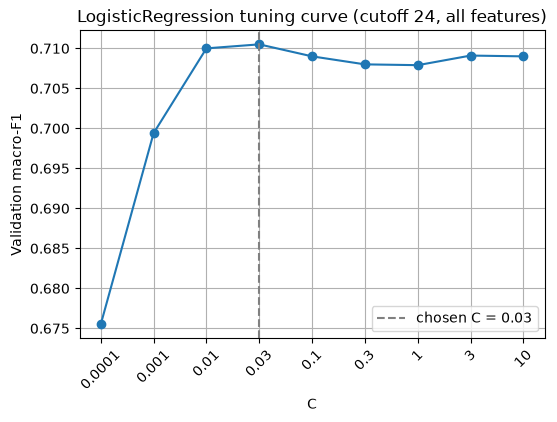

feature_set,all,background,behaviour
cutoff,,,
0,C=0.3,C=0.1,C=0.001
24,C=0.03,C=0.03,C=1
60,C=1,C=10,C=0.1
120,C=10,C=1,C=10


In [75]:
# visualize the tuning curve for the model with cutoff=24 and feature_set="all"
plot_curve("LogisticRegression", log_curve, "C")

# plot the chosen C for each logistic regression model in FEATURE_SETS x CUTOFF_DAYS
pd.DataFrame(log_rows).pivot(index="cutoff",
                             columns="feature_set",
                                values="best_param")

### 2.3 Decision Tree

#### 2.3.1 Train and tune, and produce evaluation results on test

In [76]:
# run experiment for decision tree
# tune hyperparameter max_depth on validation set
dt_rows, dt_curve, dt_pipe = run_experiment(
    "DecisionTree",
    DecisionTreeClassifier(random_state=SEED),
    "max_depth", [2, 4, 6, 8, 10, 15, 20, None])

#### 2.3.2 Sample results
Show macro-F1 by feature set × cutoff

In [77]:
# visualize the results of feature set x cutoff experiments results
dt_table = pd.DataFrame(dt_rows).pivot(index="cutoff",
                                        columns="feature_set",
                                        values="macro_f1")
display(dt_table)

feature_set,all,background,behaviour
cutoff,,,
0,0.6381,0.5935,0.6090
24,0.6696,0.5762,0.6632
60,0.7353,0.5759,0.7274
120,0.7605,0.5618,0.7661


#### 2.3.3 Tuning curve

Validation macro-F1 against `max_depth` at cutoff 24, all features. Explains the chosen value.

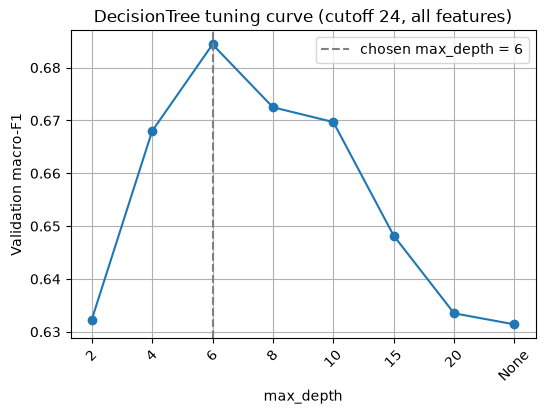

feature_set,all,background,behaviour
cutoff,,,
0,max_depth=4,max_depth=8,max_depth=6
24,max_depth=6,max_depth=2,max_depth=6
60,max_depth=8,max_depth=8,max_depth=8
120,max_depth=4,max_depth=8,max_depth=6


In [78]:
# visualize the tuning curve for the model with cutoff=24 and feature_set="all"
plot_curve("DecisionTree", dt_curve, "max_depth")

# plot the chosen max_depth for each decision tree model in FEATURE_SETS x CUTOFF_DAYS
pd.DataFrame(dt_rows).pivot(index="cutoff",
                             columns="feature_set",
                                values="best_param")

### 2.4 Random Forest

#### 2.4.1 Train and tune, and produce evaluation results on test

In [79]:
# run experiment for random forest
# tune hyperparameter min_samples_leaf on validation set
rf_rows, rf_curve, rf_pipe = run_experiment(
    "RandomForest",
    RandomForestClassifier(random_state=SEED, n_estimators=100, n_jobs=1),
    "min_samples_leaf", [1, 2, 5, 10, 20])

#### 2.4.2 Sample results
Show macro-F1 by feature set × cutoff

In [80]:
# visualize the results of feature set x cutoff experiments results
rf_table = pd.DataFrame(rf_rows).pivot(index="cutoff",
                                        columns="feature_set",
                                        values="macro_f1")
display(rf_table)

feature_set,all,background,behaviour
cutoff,,,
0,0.6565,0.6148,0.6158
24,0.7027,0.5992,0.6830
60,0.7547,0.5993,0.7456
120,0.7969,0.5655,0.7937


#### 2.4.3 Tuning curve

Validation macro-F1 against `min_samples_leaf` at cutoff 24, all features. Explains the chosen value.

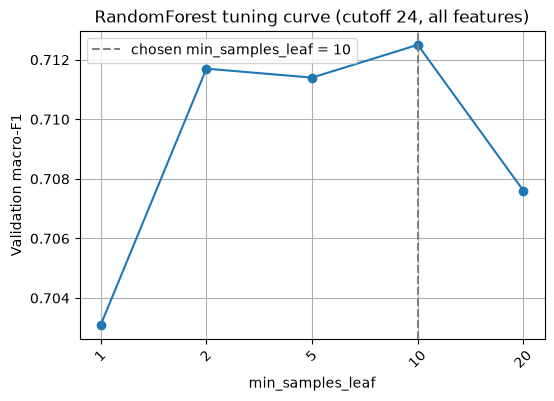

feature_set,all,background,behaviour
cutoff,,,
0,min_samples_leaf=5,min_samples_leaf=20,min_samples_leaf=5
24,min_samples_leaf=10,min_samples_leaf=20,min_samples_leaf=20
60,min_samples_leaf=2,min_samples_leaf=2,min_samples_leaf=1
120,min_samples_leaf=1,min_samples_leaf=1,min_samples_leaf=2


In [81]:
# visualize the tuning curve for the model with cutoff=24 and feature_set="all"
plot_curve("RandomForest", rf_curve, "min_samples_leaf")

# plot the chosen min_samples_leaf for each random forest model in FEATURE_SETS x CUTOFF_DAYS
pd.DataFrame(rf_rows).pivot(index="cutoff",
                             columns="feature_set",
                                values="best_param")

### 2.5 Delivery

Create deliverable for Section 4

#### 2.5.1 Combine results rows

Results are 4 models' rows containing cutoffs x feature sets, with scores available under different evaluation metrics

In [82]:
# process the deliverables for section 4 to answer RQ1 and RQ2
classical_results = pd.DataFrame(base_rows + log_rows + dt_rows + rf_rows)
assert len(classical_results) == 40
display(classical_results["model"].value_counts())

model
LogisticRegression    12
DecisionTree          12
RandomForest          12
Baseline               4
Name: count, dtype: int64

#### 2.5.2 Best model for error analysis

The model with the highest **validation** macro-F1 at cutoff 24, all features

Its pipeline goes to Section 4 as the specific case for error analysis with confusion matrix

In [83]:
# based on validation macro-F1
# find the best models' scores from each experiment
val_best = {
    "LogisticRegression": max(log_curve.values()),
    "DecisionTree": max(dt_curve.values()),
    "RandomForest": max(rf_curve.values())
}

# find the name of the best models
best_name = max(val_best, key=val_best.get)

# the best models
best_model = {
    "LogisticRegression": log_pipe,
    "DecisionTree": dt_pipe,
    "RandomForest": rf_pipe
}

# the best model pipeline
best_pipe_classical = best_model[best_name]

---

## 3. Neural Network

### 3.1 Train and tune, and produce evluation results on test
`hidden_layer_sizes` is tuned from smaller (underfit) to bigger (overfit)
Train MLPClassifier

In [84]:
# run experiment for the MLP
# tune hidden_layer_sizes (network capacity) on the validation set;
mlp_rows, mlp_curve, mlp_pipe = run_experiment(
    "MLP",
    MLPClassifier(alpha=1e-3, early_stopping=True, max_iter=400, random_state=SEED),
    "hidden_layer_sizes", [(16,), (32,), (64,), (128,), (64, 32)])

### 3.2 Sample results
Show macro-F1 by feature set × cutoff

In [85]:
# visualize the results of feature set x cutoff experiments results
mlp_table = pd.DataFrame(mlp_rows).pivot(index="cutoff",
                                        columns="feature_set",
                                        values="macro_f1")
display(mlp_table)

feature_set,all,background,behaviour
cutoff,,,
0,0.6573,0.6091,0.6221
24,0.7062,0.6019,0.6784
60,0.7612,0.5950,0.7484
120,0.7986,0.5832,0.7931


### 3.3 Tuning curve
Validation macro-F1 against `hidden_layer_sizes` at cutoff 24, all features. Explains the chosen value.

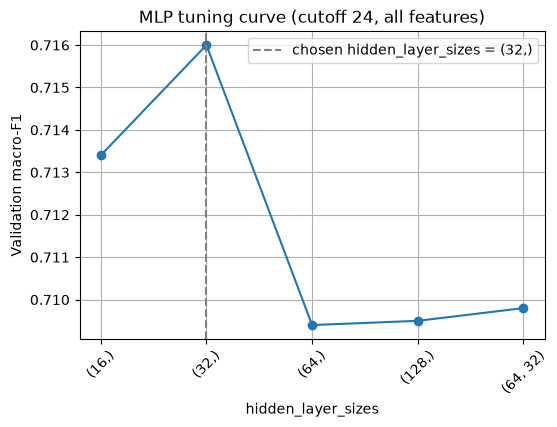

feature_set,all,background,behaviour
cutoff,,,
0,"hidden_layer_sizes=(64,)","hidden_layer_sizes=(128,)","hidden_layer_sizes=(64,)"
24,"hidden_layer_sizes=(32,)","hidden_layer_sizes=(128,)","hidden_layer_sizes=(128,)"
60,"hidden_layer_sizes=(64,)","hidden_layer_sizes=(16,)","hidden_layer_sizes=(128,)"
120,"hidden_layer_sizes=(128,)","hidden_layer_sizes=(64,)","hidden_layer_sizes=(64,)"


In [86]:
# visualize the tuning curve for the model with cutoff=24 and feature_set="all"
plot_curve("MLP", mlp_curve, "hidden_layer_sizes")

# plot the chosen min_samples_leaf for the neural network model in FEATURE_SETS x CUTOFF_DAYS
pd.DataFrame(mlp_rows).pivot(index="cutoff",
                             columns="feature_set",
                                values="best_param")

### 3.4 Delivery

Pack or name deliverables for section 4's comparision and visualisation

In [87]:
# pack the results using the same format as the classical models
mlp_results = pd.DataFrame(mlp_rows)
assert len(mlp_results) == 12
display(mlp_results["model"].value_counts())

# the best mlp model
best_pipe_mlp = mlp_pipe

model
MLP    12
Name: count, dtype: int64

---

## 4. Results

### 4.1 Visualize results to compare different feature groups' performance by cutoff days (Answers to RQ1 and RQ2)

#### 4.1.0 The statistics as in a table

In [88]:
# stack the classical and MLP results to answer RQ1 and RQ2
all_results = pd.concat([classical_results, mlp_results], ignore_index=True)
display(all_results)

# statistics to RQ1: How did models perform with the cutoff day?
rq1_table = all_results[all_results["model"] != "Baseline"]

# Macro-F1
display(rq1_table.pivot(index="cutoff", columns=["model", "feature_set"], values="macro_f1"))

# Precision
display(rq1_table.pivot(index="cutoff", columns=["model", "feature_set"], values="precision"))

# Recall
display(rq1_table.pivot(index="cutoff", columns=["model", "feature_set"], values="recall"))

,model,cutoff,feature_set,best_param,accuracy,precision,recall,f1,macro_f1,roc_auc
0,Baseline,0,—,strategy=most_frequent,0.5216,0.0000,0.0000,0.0000,0.3428,0.5000
1,Baseline,24,—,strategy=most_frequent,0.5532,0.0000,0.0000,0.0000,0.3562,0.5000
2,Baseline,60,—,strategy=most_frequent,0.5836,0.0000,0.0000,0.0000,0.3685,0.5000
3,Baseline,120,—,strategy=most_frequent,0.6210,0.0000,0.0000,0.0000,0.3831,0.5000
4,LogisticRegression,0,background,C=0.1,0.6152,0.6097,0.5436,0.5747,0.6117,0.6558
5,LogisticRegression,0,behaviour,C=0.001,0.6228,0.6171,0.5574,0.5857,0.6198,0.6629
6,LogisticRegression,0,all,C=0.3,0.6582,0.6516,0.6137,0.6321,0.6565,0.7192
7,LogisticRegression,24,background,C=0.03,0.6163,0.5933,0.4491,0.5112,0.5977,0.6438
8,LogisticRegression,24,behaviour,C=1,0.6818,0.6594,0.5952,0.6256,0.6744,0.7346
9,LogisticRegression,24,all,C=0.03,0.7168,0.7200,0.5992,0.6541,0.7072,0.7729


model       LogisticRegression                   DecisionTree                   RandomForest                          MLP                  
feature_set         background behaviour     all   background behaviour     all   background behaviour     all background behaviour     all
cutoff                                                                                                                                     
0                       0.6117    0.6198  0.6565       0.5935    0.6090  0.6381       0.6148    0.6158  0.6565     0.6091    0.6221  0.6573
24                      0.5977    0.6744  0.7072       0.5762    0.6632  0.6696       0.5992    0.6830  0.7027     0.6019    0.6784  0.7062
60                      0.5955    0.7330  0.7519       0.5759    0.7274  0.7353       0.5993    0.7456  0.7547     0.5950    0.7484  0.7612
120                     0.5714    0.7735  0.7908       0.5618    0.7661  0.7605       0.5655    0.7937  0.7969     0.5832    0.7931  0.7986

model       LogisticRegression                   DecisionTree                   RandomForest                          MLP                  
feature_set         background behaviour     all   background behaviour     all   background behaviour     all background behaviour     all
cutoff                                                                                                                                     
0                       0.6097    0.6171  0.6516       0.5978    0.6031  0.6280       0.6081    0.5996  0.6543     0.6052    0.6009  0.6617
24                      0.5933    0.6594  0.7200       0.5265    0.6237  0.6896       0.5933    0.6947  0.7178     0.5839    0.7113  0.7091
60                      0.6063    0.7592  0.7636       0.5766    0.7202  0.7375       0.5718    0.7570  0.7687     0.5837    0.7553  0.7775
120                     0.6039    0.7861  0.8032       0.5861    0.7642  0.7594       0.5047    0.8055  0.8139     0.5998    0.7918  0.8030

model       LogisticRegression                   DecisionTree                   RandomForest                          MLP                  
feature_set         background behaviour     all   background behaviour     all   background behaviour     all background behaviour     all
cutoff                                                                                                                                     
0                       0.5436    0.5574  0.6137       0.4982    0.5514  0.6042       0.5620    0.5971  0.6070     0.5454    0.6269  0.5932
24                      0.4491    0.5952  0.5992       0.5630    0.6382  0.5320       0.4543    0.5642  0.5895     0.4833    0.5304  0.6121
60                      0.3754    0.5891  0.6342       0.3499    0.6191  0.6196       0.4301    0.6246  0.6360     0.3986    0.6342  0.6433
120                     0.2769    0.6342  0.6629       0.2646    0.6368  0.6267       0.3408    0.6683  0.6683     0.3056    0.6805  0.6837

#### 4.1.1 Logistic Regression x Baseline

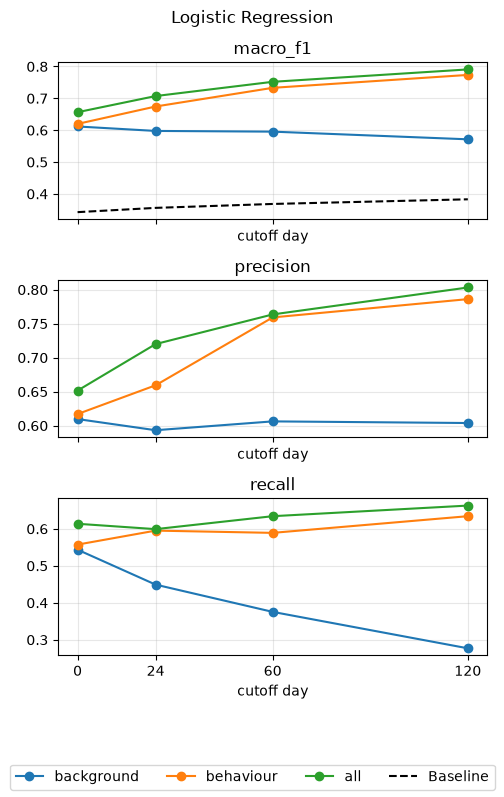

In [89]:
# plot for each evaluation metric
d = rq1_table[rq1_table["model"] == "LogisticRegression"]
fig, axes = plt.subplots(3, 1, figsize=(5, 8), sharex=True)
for ax, metric in zip(axes, ["macro_f1", "precision", "recall"]):
    for fs in ["background", "behaviour", "all"]:
        f = d[d["feature_set"] == fs]
        ax.plot(f["cutoff"], f[metric], marker="o", label=fs)
    if metric == "macro_f1":
        b = all_results[all_results["model"] == "Baseline"]
        ax.plot(b["cutoff"], b[metric], "k--", label="Baseline")
    ax.set_title(metric)
    ax.set_xticks(CUTOFF_DAYS)
    ax.set_xlabel("cutoff day")
    ax.grid(alpha=0.3)
fig.suptitle("Logistic Regression")
# one shared legend for all panels
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4)
fig.tight_layout(rect=(0, 0.1, 1, 1))
plt.show()


#### 4.1.2 Decision Tree x Baseline

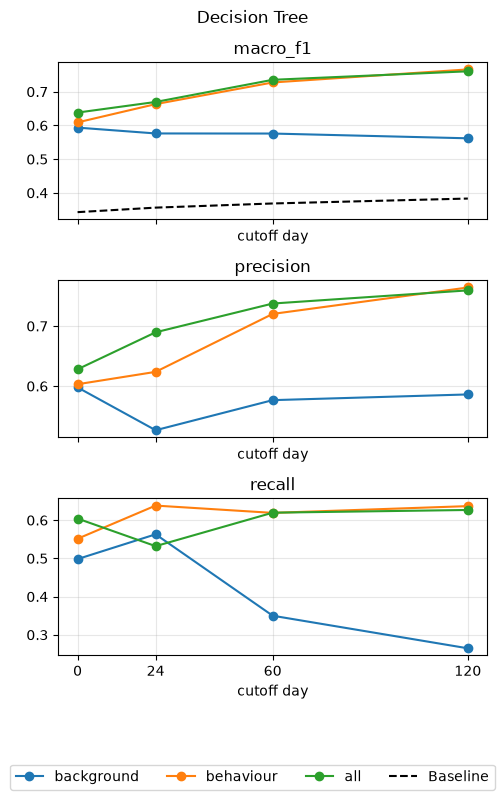

In [90]:
# plot for each evaluation metric
d = rq1_table[rq1_table["model"] == "DecisionTree"]
fig, axes = plt.subplots(3, 1, figsize=(5, 8), sharex=True)
for ax, metric in zip(axes, ["macro_f1", "precision", "recall"]):
    for fs in ["background", "behaviour", "all"]:
        f = d[d["feature_set"] == fs]
        ax.plot(f["cutoff"], f[metric], marker="o", label=fs)
    if metric == "macro_f1":
        b = all_results[all_results["model"] == "Baseline"]
        ax.plot(b["cutoff"], b[metric], "k--", label="Baseline")
    ax.set_title(metric)
    ax.set_xticks(CUTOFF_DAYS)
    ax.set_xlabel("cutoff day")
    ax.grid(alpha=0.3)
fig.suptitle("Decision Tree")
# one shared legend for all panels
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4)
fig.tight_layout(rect=(0, 0.1, 1, 1))
plt.show()

#### 4.1.3 Random Forest x Baseline

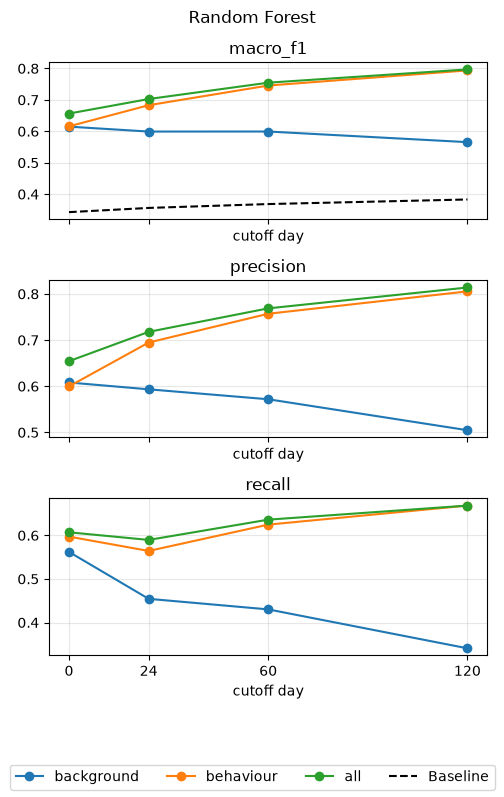

In [91]:
# plot for each evaluation metric
d = rq1_table[rq1_table["model"] == "RandomForest"]
fig, axes = plt.subplots(3, 1, figsize=(5, 8), sharex=True)
for ax, metric in zip(axes, ["macro_f1", "precision", "recall"]):
    for fs in ["background", "behaviour", "all"]:
        f = d[d["feature_set"] == fs]
        ax.plot(f["cutoff"], f[metric], marker="o", label=fs)
    if metric == "macro_f1":
        b = all_results[all_results["model"] == "Baseline"]
        ax.plot(b["cutoff"], b[metric], "k--", label="Baseline")
    ax.set_title(metric)
    ax.set_xticks(CUTOFF_DAYS)
    ax.set_xlabel("cutoff day")
    ax.grid(alpha=0.3)
fig.suptitle("Random Forest")
# one shared legend for all panels
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4)
fig.tight_layout(rect=(0, 0.1, 1, 1))
plt.show()

#### 4.1.4 MLP x Baseline

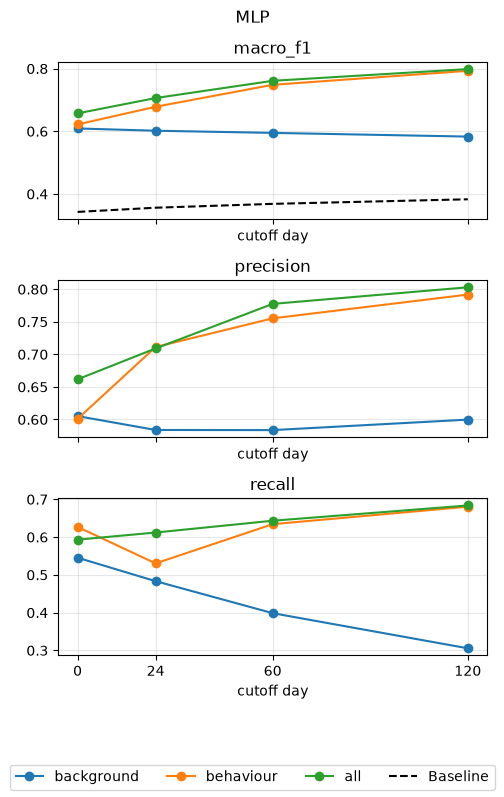

In [92]:
# plot for each evaluation metric
d = rq1_table[rq1_table["model"] == "MLP"]
fig, axes = plt.subplots(3, 1, figsize=(5, 8), sharex=True)
for ax, metric in zip(axes, ["macro_f1", "precision", "recall"]):
    for fs in ["background", "behaviour", "all"]:
        f = d[d["feature_set"] == fs]
        ax.plot(f["cutoff"], f[metric], marker="o", label=fs)
    if metric == "macro_f1":
        b = all_results[all_results["model"] == "Baseline"]
        ax.plot(b["cutoff"], b[metric], "k--", label="Baseline")
    ax.set_title(metric)
    ax.set_xticks(CUTOFF_DAYS)
    ax.set_xlabel("cutoff day")
    ax.grid(alpha=0.3)
fig.suptitle("MLP")
# one shared legend for all panels
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4)
fig.tight_layout(rect=(0, 0.1, 1, 1))
plt.show()

#### 4.1.5 Conclusion and Comparison

Show the settings for the best model of each method

In [93]:
# Show the best models and their corresponding setting and Macro-F1 score
best_rows = rq1_table.loc[rq1_table.groupby("model")["macro_f1"].idxmax()]
baseline_rows = all_results[all_results["model"] == "Baseline"]
summary = pd.concat([baseline_rows, best_rows], ignore_index=True)
display(summary[["model", "cutoff", "feature_set", "best_param", "macro_f1", "precision", "recall"]])

,model,cutoff,feature_set,best_param,macro_f1,precision,recall
0,Baseline,0,—,strategy=most_frequent,0.3428,0.0000,0.0000
1,Baseline,24,—,strategy=most_frequent,0.3562,0.0000,0.0000
2,Baseline,60,—,strategy=most_frequent,0.3685,0.0000,0.0000
3,Baseline,120,—,strategy=most_frequent,0.3831,0.0000,0.0000
4,DecisionTree,120,behaviour,max_depth=6,0.7661,0.7642,0.6368
5,LogisticRegression,120,all,C=10,0.7908,0.8032,0.6629
6,MLP,120,all,"hidden_layer_sizes=(128,)",0.7986,0.8030,0.6837
7,RandomForest,120,all,min_samples_leaf=1,0.7969,0.8139,0.6683


### 4.2 Error Analysis

#### 4.2.1 Plot confusion matrix for the best classical model

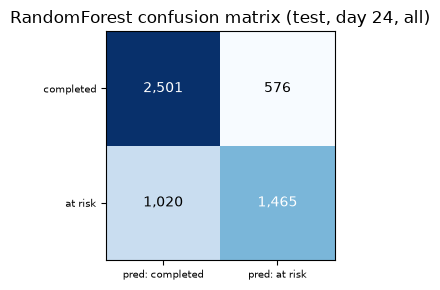

TN=2,501 FP=576 FN=1,020 TP=1,465


In [94]:
train, val, test = SPLITS[24]
cols = FEATURE_SETS["all"]
proba = best_pipe_classical.predict_proba(test[cols])[:, 1]
pred = (proba >= 0.5).astype(int)
y = test[TARGET].values

cm = confusion_matrix(y, pred)
plt.figure(figsize=(3.4, 3))
plt.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        plt.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() * .55 else "black")
plt.xticks([0, 1], ["pred: completed", "pred: at risk"], fontsize=7)
plt.yticks([0, 1], ["completed", "at risk"], fontsize=7)
plt.title(f"{best_name} confusion matrix (test, day 24, all)")
plt.tight_layout(); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn:,} FP={fp:,} FN={fn:,} TP={tp:,}")

#### 4.2.2 Plot confusion matrix for the MLP model

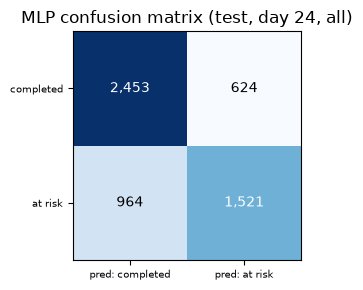

TN=2,453 FP=624 FN=964 TP=1,521


In [95]:
train, val, test = SPLITS[24]
cols = FEATURE_SETS["all"]
proba = best_pipe_mlp.predict_proba(test[cols])[:, 1]
pred = (proba >= 0.5).astype(int)
y = test[TARGET].values

cm = confusion_matrix(y, pred)
plt.figure(figsize=(3.4, 3))
plt.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        plt.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() * .55 else "black")
plt.xticks([0, 1], ["pred: completed", "pred: at risk"], fontsize=7)
plt.yticks([0, 1], ["completed", "at risk"], fontsize=7)
plt.title("MLP confusion matrix (test, day 24, all)")
plt.tight_layout(); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn:,} FP={fp:,} FN={fn:,} TP={tp:,}")

#### 4.2.3 Error analysis: the characteristic of a subject
"Module" is a core concept in the processed dataset. It is a specific subject, while "Presentation" is a specific run of that subject, and the (Module, Presentation, Student) triple is the enrollment

In [96]:
# specific case: which modules does the MLP miss at-risk students in, and why?
ea = test[["code_module", "has_asm_activity", TARGET]].copy()
ea["pred"] = pred
display(ea.groupby("code_module").apply(lambda g: pd.Series({
    "recall": g.loc[g[TARGET] == 1, "pred"].mean(),
    "no_submission_%": (g["has_asm_activity"] == 0).mean() * 100,
})).round(3))

,recall,no_submission_%
code_module,,
AAA,0.207,11.429
BBB,0.566,13.297
CCC,0.730,11.293
DDD,0.739,35.939
EEE,0.424,95.984
FFF,0.616,13.150
GGG,0.404,98.453
